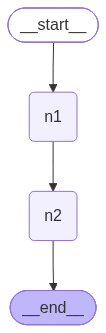

In [1]:
from typing import TypedDict
from IPython.display import Image, display
from langgraph.constants import START, END
from langgraph.graph import StateGraph


# ============1.State=================
class DefaultReducerState(TypedDict):
    val: str

# ============2.Node=================
def node_1(state: DefaultReducerState):
    print(f"node_1 接收到了 State：{state}")
    return {"val": "node_1 value"}

def node_2(state: DefaultReducerState):
    print(f"node_2 接收到了 State：{state}")
    return {"val": "node_2 value"}

# ============3.Edge连接Node，形成Graph=================
builder = StateGraph(DefaultReducerState)

builder.add_node("n1", node_1)
builder.add_node("n2", node_2)

builder.add_edge(START, "n1")
builder.add_edge("n1", "n2")
builder.add_edge("n2", END)

graph = builder.compile()

display(Image(graph.get_graph(xray=True).draw_mermaid_png()))

In [2]:
# ============4.调用Graph=================
result = graph.invoke({"val": "init value"})

print(result)

node_1 接收到了 State：{'val': 'init value'}
node_2 接收到了 State：{'val': 'node_1 value'}
{'val': 'node_2 value'}
